# Distance Metrics for Pattern-Matching NILM

This notebook measures how similar each **query window** (validation and test data) is to each **template window** (training data). Pattern-matching NILM uses these scores later: for a given query, it looks up the closest template and uses its appliance-level consumption as the disaggregation estimate.

Three comparison methods are computed on the **normalized aggregate signal** (all electrical quantities):

| Metric | What it compares | Better match | Speed |
|---|---|---|---|
| **Feature distance** | Summary statistics (mean, min, max, std, RMS, energy) of each window | lower | fastest |
| **Pearson correlation** | Shape of each channel's time series, ignoring offset and scale | higher | fast |
| **Dynamic time warping (DTW)** | Point-by-point shape, allowing points to be stretched or shifted in time | lower | slowest |

### How to use it

1. Run `data_generation.py` first.
2. Set `DATASET_NAME` in **Configuration** (use one of the `ampds_pattern_matching_*` datasets).
3. Run all cells. Results are written to `results/<DATASET_NAME>/`.

### Notation

| Symbol | Meaning |
|---|---|
| $N_t$ | number of template (training) windows |
| $N_q$ | number of query (validation + test) windows |
| $L$ | window length in timesteps |
| $C$ | number of aggregate electrical quantities (channels) |
| $F$ | number of summary features per channel |

Each metric is stored as an $N_q \times N_t$ matrix. **Rows are queries, columns are templates.**

## 1. Setup
### Imports

In [14]:
import os
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.format import open_memmap
from numpy.lib.stride_tricks import sliding_window_view
from scipy.spatial.distance import cdist
from tqdm.auto import tqdm

### Configuration

Every user-adjustable setting is in this cell.

- **`DATASET_NAME`**: which file in `processed_data/` to load. The `ampds_CNN_*` datasets use `stride=1`, so the number of window pairs is about 900× larger. Make sure to use a **Pattern Matching** dataset, not a CNN dataset.
- **`DTW_BAND`**: Sakoe–Chiba band radius, in timesteps. `None` places no constraint on the warping path, which gives exact, unconstrained DTW. A small radius such as `5` stops DTW from aligning points that are far apart in time and makes DTW about 3× faster.
- **`QUERY_BATCH`** and **`DTW_TEMPLATE_BLOCK`**: control memory use and speed only. They do not change the results.

In [28]:
# --- Dataset -----------------------------------------------------------------
DATASET_NAME = 'ampds_pattern_matching_1week'   # or 'ampds_pattern_matching_2year'
LOCAL_TIMEZONE = 'America/Vancouver'             # AMPds was recorded in Burnaby, BC

# --- Metrics -----------------------------------------------------------------
FEATURE_NAMES = ('mean', 'min', 'max', 'std', 'rms')
DTW_BAND = None                  # Sakoe-Chiba radius in timesteps; None = unconstrained

# --- Performance / memory ------------------------------------------------------
QUERY_BATCH = 512                # queries per batch (feature distance, Pearson)
DTW_TEMPLATE_BLOCK = 4096        # templates per block inside the DTW kernel
MAX_OUTPUT_GB = 16.0             # refuse to start if the metric matrices would exceed this

# --- Plotting ----------------------------------------------------------------
EXAMPLE_QUERY_POS = 0            # which query (row) to use in the example figures
SPLIT_COLORS = {'train': '#2a78d6', 'val': '#eb6834', 'test': '#1baf7a'}
METRIC_COLORS = {'feature_distance': '#eda100', 'pearson_correlation': '#e87ba4', 'dtw_distance': '#008300'}
QUERY_COLOR = '#333333'

# Metric metadata used throughout the notebook.
METRICS = {
    'feature_distance':    {'label': 'Feature distance',    'better': 'lower'},
    'pearson_correlation': {'label': 'Pearson correlation', 'better': 'higher'},
    'dtw_distance':        {'label': 'DTW distance',        'better': 'lower'}}

### Directories

The paths follow the layout `data_generation.py` uses: `processed_data/` and `results/` sit one level above `notebooks/`. Each dataset gets its own results subfolder, so running the notebook on another dataset never overwrites earlier results.

In [16]:
notebooks_dir = os.getcwd()
base_dir = os.path.abspath(os.path.join(notebooks_dir, '..'))
processed_data_dir = os.path.join(base_dir, 'processed_data')

results_dir = os.path.join(base_dir, 'results', DATASET_NAME)
os.makedirs(results_dir, exist_ok=True)

print(f'Processed data: {processed_data_dir}')
print(f'Results:        {results_dir}')

Processed data: c:\Users\codett\Documents\GitHub\Differential-Privacy-PESGM2026\processed_data
Results:        c:\Users\codett\Documents\GitHub\Differential-Privacy-PESGM2026\results\ampds_pattern_matching_1week


## 2. Load the processed dataset

`data_generation.py` writes one compressed `.npz` file per dataset with these contents:

| Key | Shape | Description |
|---|---|---|
| `electrical_quantities` | $(C,)$ | Aggregate channel names, e.g. `P`, `I`, `Q`, `S` |
| `appliance_names` | $(A,)$ | Target appliances, e.g. `HPE`, `FRE` |
| `datetimes` | $(T_{raw},)$ | Timestamp of every row (Unix seconds) |
| `agg_data` / `agg_norm` | $(T_{raw}, C)$ | Aggregate signal, raw / min–max normalized. Removed appliances (`RSE`) have been subtracted from real power. |
| `apps_data` / `apps_norm` | $(T_{raw}, A)$ | Target-appliance real power, raw / normalized |
| `agg_min`, `agg_max`, `apps_min`, `apps_max` | $(C,)$ / $(A,)$ | Normalization constants, computed only from timesteps that training windows cover |
| `train_indices`, `val_indices`, `test_indices` | $(N,)$ | **Start** row of every window in each split (shuffled) |
| `train_val_test_split` | $(3,)$ | Split proportions *actually achieved* (by window count) |
| `T` | scalar | Number of unique timesteps covered by any window |
| `window_length`, `stride`, `chunk_size`, `num_chunks` | scalars | Windowing and chunking parameters |
| `time_resolution`, `time_units` | scalars | Sampling interval, e.g. `60` `'seconds'` |

In [17]:
processed_data_filepath = os.path.join(processed_data_dir, f'{DATASET_NAME}.npz')
data = np.load(processed_data_filepath, allow_pickle=False)

print(f'Loaded {os.path.basename(processed_data_filepath)}')
print(f'Items: {data.files}')

Loaded ampds_pattern_matching_1week.npz
Items: ['electrical_quantities', 'appliance_names', 'datetimes', 'elapsed_seconds', 'timezone', 'agg_data', 'apps_data', 'agg_norm', 'apps_norm', 'agg_min', 'agg_max', 'apps_min', 'apps_max', 'train_indices', 'val_indices', 'test_indices', 'train_val_test_split', 'T', 'window_length', 'stride', 'chunk_size', 'num_chunks', 'time_resolution', 'time_units']


Unpack everything into ordinary Python and NumPy objects. Scalars are stored as 0-d arrays, so they are cast explicitly.

In [18]:
electrical_quantities = data['electrical_quantities'].tolist()
appliance_names = data['appliance_names'].tolist()

datetimes_raw = data['datetimes']
agg_data, agg_norm = data['agg_data'], data['agg_norm']
apps_data, apps_norm = data['apps_data'], data['apps_norm']

train_indices = data['train_indices'].astype(np.int64)
val_indices = data['val_indices'].astype(np.int64)
test_indices = data['test_indices'].astype(np.int64)

window_length = int(data['window_length'])
stride = int(data['stride'])
chunk_size = int(data['chunk_size'])
num_chunks = int(data['num_chunks'])
time_resolution = int(data['time_resolution'])
time_units = str(data['time_units'])
num_covered_timesteps = int(data['T'])
achieved_split = np.asarray(data['train_val_test_split'], dtype=float)

num_timesteps = len(datetimes_raw)
num_channels = len(electrical_quantities)

Unix timestamps are converted to local time for display only. Every computation uses row positions.

In [19]:
def to_local_datetimes(raw, tz=LOCAL_TIMEZONE):
    """Convert Unix-second timestamps to a tz-aware DatetimeIndex (returns None if they don't look like Unix time)."""
    raw = np.asarray(raw, dtype=float)
    if raw.size == 0 or np.nanmin(raw) < 1e8:  # 1e8 s is March 1973: anything smaller is not Unix time
        return None
    return pd.to_datetime(raw, unit='s', utc=True).tz_convert(tz)

datetimes = to_local_datetimes(datetimes_raw)

summary = pd.Series({
    'Dataset': DATASET_NAME,
    'Recording span': (f'{datetimes[0]:%Y-%m-%d %H:%M} → {datetimes[-1]:%Y-%m-%d %H:%M} ({LOCAL_TIMEZONE})'
                       if datetimes is not None else 'n/a'),
    'Rows in recording': f'{num_timesteps:,}',
    'Unique timesteps covered by windows': f'{num_covered_timesteps:,}',
    'Time resolution': f'{time_resolution} {time_units}',
    'Electrical quantities': ', '.join(electrical_quantities),
    'Target appliances': ', '.join(appliance_names),
    'Window length / stride': f'{window_length} / {stride}',
    'Chunk size / number of chunks': f'{chunk_size} / {num_chunks}',
}, name='Value')
display(summary.to_frame())

,Value
Dataset,ampds_pattern_matching_1week
Recording span,2012-04-01 00:00 → 2012-04-07 23:59 (America/V...
Rows in recording,"10,080"
Unique timesteps covered by windows,"10,080"
Time resolution,60 seconds
Electrical quantities,"P-agg, I-agg, Q-agg, S-agg"
Target appliances,"HPE, FRE"
Window length / stride,30 / 30
Chunk size / number of chunks,1440 / 7


### Preview the signals

The first rows of the aggregate and appliance data, raw and normalized. Normalized values are close to $[0, 1]$, but they can go slightly outside that range in validation and test rows, because the minimum and maximum come from training rows only.

In [20]:
def preview_table(values, columns, caption, n=5, fmt='{:.3f}'):
    df = pd.DataFrame(values[:n], columns=columns)
    if datetimes is not None:
        df.insert(0, 'datetime', datetimes[:n].strftime('%Y-%m-%d %H:%M'))
    return df.style.format(fmt, subset=columns).set_caption(caption).hide(axis='index')

display(preview_table(agg_data, electrical_quantities, 'Aggregate measurements (raw)'))
display(preview_table(agg_norm, electrical_quantities, 'Aggregate measurements (normalized)'))
display(preview_table(apps_data, appliance_names, 'Target appliances: real power (raw)'))
display(preview_table(apps_norm, appliance_names, 'Target appliances: real power (normalized)'))

datetime,P-agg,I-agg,Q-agg,S-agg
2012-04-01 00:00,875.000,8.300,141.000,1037.000
2012-04-01 00:01,870.000,8.200,141.000,1028.000
2012-04-01 00:02,829.000,8.000,139.000,993.000
2012-04-01 00:03,829.000,8.000,141.000,990.000
2012-04-01 00:04,731.000,7.800,140.000,988.000


datetime,P-agg,I-agg,Q-agg,S-agg
2012-04-01 00:00,0.093,0.053,0.042,0.080
2012-04-01 00:01,0.092,0.052,0.042,0.079
2012-04-01 00:02,0.086,0.049,0.041,0.073
2012-04-01 00:03,0.086,0.049,0.042,0.073
2012-04-01 00:04,0.071,0.047,0.041,0.073


datetime,HPE,FRE
2012-04-01 00:00,36.000,106.000
2012-04-01 00:01,37.000,107.000
2012-04-01 00:02,38.000,107.000
2012-04-01 00:03,37.000,106.000
2012-04-01 00:04,36.000,106.000


datetime,HPE,FRE
2012-04-01 00:00,0.015,0.018
2012-04-01 00:01,0.015,0.022
2012-04-01 00:02,0.016,0.022
2012-04-01 00:03,0.015,0.018
2012-04-01 00:04,0.015,0.018


The figure below plots one full day (one chunk) so the patterns that will be matched are visible. The top panel shows aggregate real power, from which `RSE` has already been removed. The panels below show the target appliances.

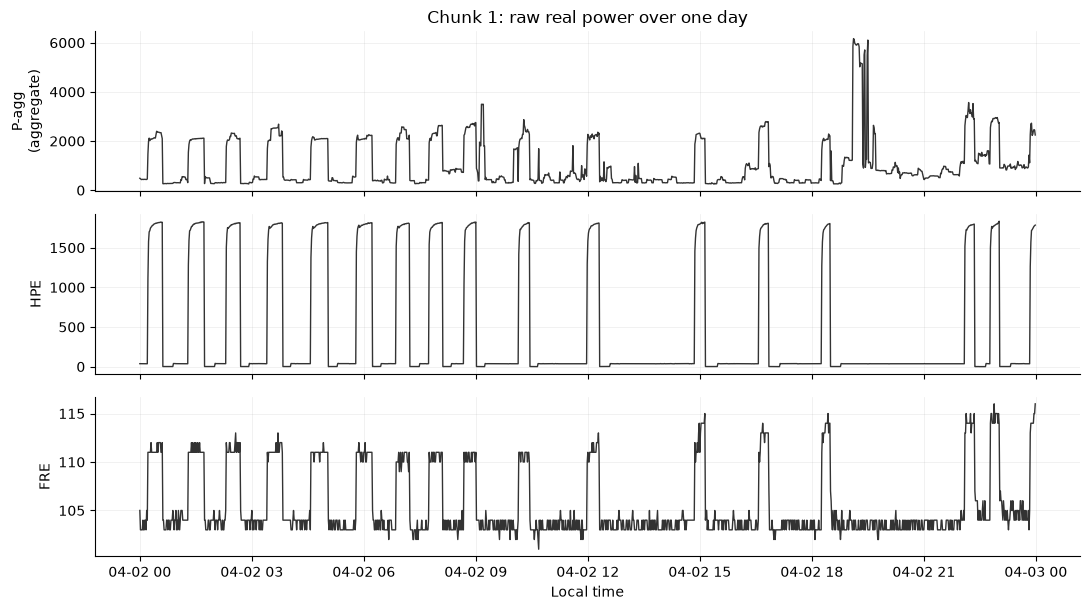

In [21]:
def chunk_boundaries():
    """Recreate the chunk boundaries used by data_generation.precompute_indices."""
    return np.linspace(0, num_timesteps, num_chunks + 1, dtype=int)

boundaries = chunk_boundaries()
example_chunk = int(np.searchsorted(boundaries, train_indices[0], side='right') - 1)
day = slice(boundaries[example_chunk], boundaries[example_chunk + 1])
x_day = datetimes[day] if datetimes is not None else np.arange(day.start, day.stop)

n_panels = 1 + len(appliance_names)
fig, axes = plt.subplots(n_panels, 1, figsize=(11, 1.9 * n_panels + 0.5), sharex=True)
axes[0].plot(x_day, agg_data[day, 0], color=QUERY_COLOR, lw=1)
axes[0].set_ylabel(f'{electrical_quantities[0]}\n(aggregate)')
for ax, k, name in zip(axes[1:], range(len(appliance_names)), appliance_names):
    ax.plot(x_day, apps_data[day, k], color=QUERY_COLOR, lw=1)
    ax.set_ylabel(name)
for ax in axes:
    ax.grid(alpha=0.25, lw=0.5)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_title(f'Chunk {example_chunk}: raw real power over one day')
axes[-1].set_xlabel('Local time' if datetimes is not None else 'Row')
fig.tight_layout()
plt.show()

## 3. Train / validation / test splits

`data_generation.py` cuts the timeline into `num_chunks` contiguous chunks of about one day each. It assigns **whole chunks** to train, validation or test, and keeps only windows that fit entirely inside one chunk. This prevents leakage: a test window never overlaps a training window in time.

The cells below rebuild the chunk assignment from the saved window starts, confirm that no chunk is shared between splits, and compare the requested and achieved split proportions. Because whole chunks are assigned, the achieved proportions can differ noticeably from 70/15/15 on small datasets.

In [22]:
splits = {'train': train_indices, 'val': val_indices, 'test': test_indices}

window_chunk = {name: np.searchsorted(boundaries, idx, side='right') - 1 for name, idx in splits.items()}
chunk_split = np.full(num_chunks, '', dtype=object)
for name, chunks in window_chunk.items():
    for c in np.unique(chunks):
        assert chunk_split[c] in ('', name), f'Chunk {c} appears in both {chunk_split[c]} and {name}!'
        chunk_split[c] = name

# Every window must end inside its own chunk
for name, idx in splits.items():
    assert np.all(idx + window_length <= boundaries[window_chunk[name] + 1]), f'{name} window crosses a chunk boundary'

split_table = pd.DataFrame({
    'chunks': [int((chunk_split == n).sum()) for n in splits],
    'windows': [len(idx) for idx in splits.values()],
    'achieved proportion': achieved_split,
}, index=list(splits))
display(split_table.style.format({'achieved proportion': '{:.3f}'}).set_caption('Split summary'))

for name, idx in splits.items():
    print(f'{name:>5} window starts ({len(idx)} total): {idx[:8]} ...')
print('No chunk is shared between splits.')

,chunks,windows,achieved proportion
train,5,240,0.714
val,1,48,0.143
test,1,48,0.143


train window starts (240 total): [2730 8970 9810 3540 8940 4410 9780 8640] ...
  val window starts (48 total): [8370 7350 7230 8130 8070 8400 7560 8340] ...
 test window starts (48 total): [1200 1320    0  240  810  150   60 1230] ...
No chunk is shared between splits.


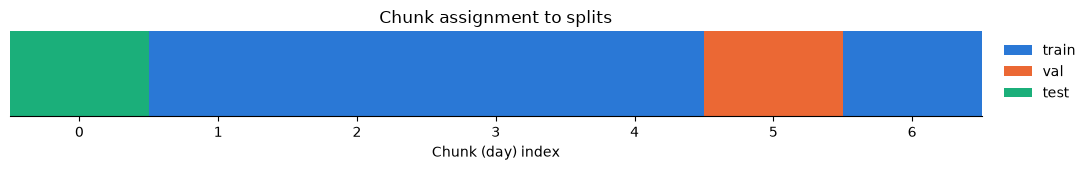

In [23]:
fig, ax = plt.subplots(figsize=(11, 1.8))
for name, color in SPLIT_COLORS.items():
    chunks = np.flatnonzero(chunk_split == name)
    ax.bar(chunks, 1, width=1.0, color=color, label=name, edgecolor='none')
ax.set_yticks([])
ax.set_ylim(0, 1)
ax.set_xlim(-0.5, num_chunks - 0.5)
ax.set_xlabel('Chunk (day) index')
ax.set_title('Chunk assignment to splits')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
ax.spines[['top', 'right', 'left']].set_visible(False)
fig.tight_layout()
plt.show()

## 4. Templates and queries

Pattern-matching algorithms compare new inputs with examples stored from the training data. The normalized data and the window start indices already define those examples, so no separate template database is built.

- **Templates**: every training window, $N_t$ of them.
- **Queries**: every validation window followed by every test window, $N_q$ of them. `query_split` records which split each query row came from.

`extract_windows` returns a contiguous array of shape $(N, L, C)$. Order: window, timestep, channel.

In [29]:
def extract_windows(x, starts, length):
    """Stack x[s : s + length] for every start s -> array of shape (len(starts), length, x.shape[1])."""
    view = sliding_window_view(x, length, axis=0)            # (T - length + 1, C, length), no copy
    return np.ascontiguousarray(view[starts].transpose(0, 2, 1), dtype=np.float64)

template_indices = train_indices
query_indices = np.concatenate([val_indices, test_indices])
query_split = np.array(['val'] * len(val_indices) + ['test'] * len(test_indices))

template_windows = extract_windows(agg_norm, template_indices, window_length)
query_windows = extract_windows(agg_norm, query_indices, window_length)

n_templates, n_queries = len(template_indices), len(query_indices)
print(f'Template windows: {template_windows.shape}  (N_t, L, C)')
print(f'Query windows:    {query_windows.shape}  (N_q, L, C)')

Template windows: (240, 30, 4)  (N_t, L, C)
Query windows:    (96, 30, 4)  (N_q, L, C)


## 5. Output storage and size check

The old notebook kept results in Python dictionaries keyed by `(template_idx, query_idx)`. That works for a few hundred thousand pairs. The two-year dataset has hundreds of millions of pairs, which would need far too much memory as a dictionary. Each metric is therefore written directly to disk as a `float32` matrix of shape $(N_q, N_t)$ using `open_memmap`. These files can be reopened later without loading them fully into memory, using `np.load(..., mmap_mode='r')`.

Matrix position `[q, t]` maps back to the original windows through the index arrays:

```python
template_idx = template_indices[t]   # start row of the training window
query_idx    = query_indices[q]      # start row of the validation/test window
```

In [30]:
n_pairs = n_queries * n_templates
gb_per_metric = n_pairs * 4 / 1e9
print(f'{n_queries:,} queries × {n_templates:,} templates = {n_pairs:,} pairs')
print(f'{gb_per_metric:.3f} GB per metric, {gb_per_metric * len(METRICS):.3f} GB total on disk')

if gb_per_metric * len(METRICS) > MAX_OUTPUT_GB:
    raise MemoryError(
        f'Output would be {gb_per_metric * len(METRICS):.1f} GB (> MAX_OUTPUT_GB={MAX_OUTPUT_GB}). '
        'Use a pattern-matching dataset (stride = window length) or raise MAX_OUTPUT_GB.')

def new_metric_matrix(metric):
    path = os.path.join(results_dir, f'{metric}.npy')
    return open_memmap(path, mode='w+', dtype=np.float32, shape=(n_queries, n_templates))

metric_matrices = {}

96 queries × 240 templates = 23,040 pairs
0.000 GB per metric, 0.000 GB total on disk


## 6. Metric 1: Feature distance

### Feature matrices

Each window is summarized by $F$ statistics, computed **separately for each channel**. Because the window has $C$ channels, the result is a $C \times F$ matrix rather than a vector:

| Feature | Definition (per channel, over the $L$ timesteps) |
|---|---|
| mean | $\frac{1}{L}\sum_t x_t$ |
| min / max | $\min_t x_t$, $\max_t x_t$ |
| std | population standard deviation |
| rms | $\sqrt{\frac{1}{L}\sum_t x_t^2}$ |
| energy | $\sum_t x_t^2$ |

> **Note on scale:** features are not rescaled before the distance is taken. Each of the features stay at or below 1. This may not necessarily be true for other features. Features with larger magnitudes may dominate the distance.

In [31]:
FEATURE_FUNCS = {
    'mean':   lambda w: w.mean(axis=1),
    'min':    lambda w: w.min(axis=1),
    'max':    lambda w: w.max(axis=1),
    'std':    lambda w: w.std(axis=1),
    'rms':    lambda w: np.sqrt(np.mean(w ** 2, axis=1)),
}

def compute_feature_matrices(windows, feature_names=FEATURE_NAMES):
    """(N, L, C) windows -> (N, C, F) feature matrices (rows = channels, columns = features)."""
    return np.stack([FEATURE_FUNCS[name](windows) for name in feature_names], axis=-1)

template_features = compute_feature_matrices(template_windows)
query_features = compute_feature_matrices(query_windows)
print(f'Template features: {template_features.shape}  (N_t, C, F)')
print(f'Query features:    {query_features.shape}  (N_q, C, F)')

Template features: (240, 4, 5)  (N_t, C, F)
Query features:    (96, 4, 5)  (N_q, C, F)


The feature matrix of one example template window:

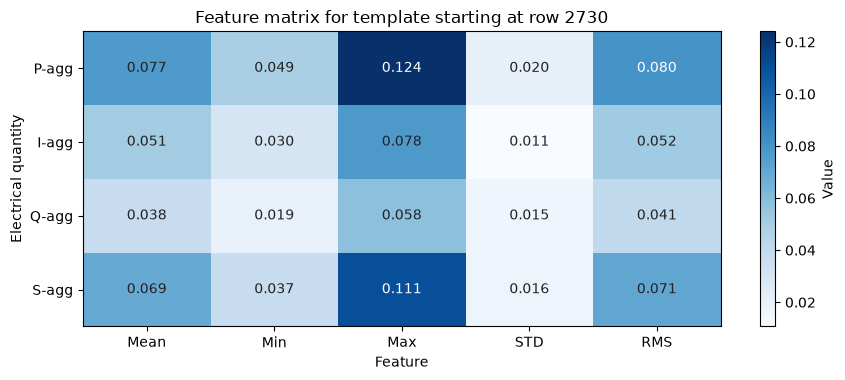

In [32]:
feature_matrix = template_features[0]

fig, ax = plt.subplots(figsize=(9, 0.6 * num_channels + 1.5))
im = ax.imshow(feature_matrix, aspect='auto', cmap='Blues')
ax.set_xticks(range(len(FEATURE_NAMES)), labels=[f.upper() if f in ('rms', 'std') else f.title() for f in FEATURE_NAMES])
ax.set_yticks(range(num_channels), labels=electrical_quantities)
ax.set_xlabel('Feature')
ax.set_ylabel('Electrical quantity')
ax.set_title(f'Feature matrix for template starting at row {template_indices[0]}')
threshold = feature_matrix.min() + 0.6 * np.ptp(feature_matrix)
for r in range(feature_matrix.shape[0]):
    for c in range(feature_matrix.shape[1]):
        v = feature_matrix[r, c]
        ax.text(c, r, f'{v:.3f}', ha='center', va='center', color='white' if v > threshold else '#222222')
fig.colorbar(im, ax=ax, label='Value')
fig.tight_layout()
plt.show()

### Pairwise feature distance

The distance between two feature matrices is their **Frobenius norm** distance, the square root of the summed squared element-wise differences:

$$d_{feat}(A, B) = \lVert A - B \rVert_F = \sqrt{\sum_{c,f} (A_{cf} - B_{cf})^2}$$

This equals the ordinary Euclidean distance between the two flattened matrices, so `scipy.spatial.distance.cdist` computes a whole batch of queries against all templates in one call.

In [33]:
def pairwise_feature_distance(query_feats, template_feats, out, batch=QUERY_BATCH):
    """Frobenius distance between every query and template feature matrix, written into out[q, t]."""
    q_flat = query_feats.reshape(len(query_feats), -1)
    t_flat = template_feats.reshape(len(template_feats), -1)
    for start in tqdm(range(0, len(q_flat), batch), desc='Feature distance'):
        stop = start + batch
        out[start:stop] = cdist(q_flat[start:stop], t_flat, metric='euclidean')
    return out

t0 = time.perf_counter()
metric_matrices['feature_distance'] = pairwise_feature_distance(
    query_features, template_features, new_metric_matrix('feature_distance'))
print(f'Done in {time.perf_counter() - t0:.1f} s')

Feature distance:   0%|          | 0/1 [00:00<?, ?it/s]

Done in 0.0 s


## 7. Metric 2: Pearson correlation

Pearson correlation measures how strongly two series move together **linearly**. It ignores differences in offset and scale, so it compares shape alone. For channel $c$:

$$r_c = \frac{1}{L}\sum_{t} z^{q}_{t,c}\, z^{\tau}_{t,c}, \qquad z_{t,c} = \frac{x_{t,c} - \bar{x}_c}{\sigma_c}$$

where $q$ is the query, $\tau$ the template, and $\sigma_c$ the population standard deviation. The reported score is the **mean absolute correlation across channels**:

$$s_{pearson} = \frac{1}{C}\sum_c |r_c| \in [0, 1]$$

**Higher means more similar.** This is a similarity score, not a distance.

Two implementation details:

- **Vectorized:** after each window is z-scored once, every correlation in a batch comes from a single matrix product per channel, `Zq @ Zt.T / L`. This replaces about $N_q N_t C$ calls to `np.corrcoef`.
- **Flat windows:** if a channel is constant within a window, $\sigma_c = 0$ and correlation is undefined. Those channels contribute $r_c = 0$, meaning "no linear relationship", instead of making the whole score `NaN`. The old code returned `NaN` in this case.

> Taking the absolute value treats perfectly *opposite* shapes ($r = -1$) as perfect matches.

In [34]:
def zscore_windows(windows, eps=1e-12):
    """Standardize each channel of each window over time; constant channels become all zeros."""
    centered = windows - windows.mean(axis=1, keepdims=True)
    std = centered.std(axis=1, keepdims=True)
    return np.divide(centered, std, out=np.zeros_like(centered), where=std > eps)

def pairwise_pearson(query_windows, template_windows, out, batch=QUERY_BATCH):
    """Mean |Pearson r| across channels for every query/template pair, written into out[q, t]."""
    length, channels = query_windows.shape[1], query_windows.shape[2]
    zq = zscore_windows(query_windows)
    zt_per_channel = [np.ascontiguousarray(zscore_windows(template_windows)[:, :, c]) for c in range(channels)]
    for start in tqdm(range(0, len(zq), batch), desc='Pearson correlation'):
        stop = start + batch
        acc = np.zeros((len(zq[start:stop]), len(template_windows)))
        for c in range(channels):
            acc += np.abs(zq[start:stop, :, c] @ zt_per_channel[c].T)
        out[start:stop] = acc / (length * channels)
    return out

t0 = time.perf_counter()
metric_matrices['pearson_correlation'] = pairwise_pearson(
    query_windows, template_windows, new_metric_matrix('pearson_correlation'))
print(f'Done in {time.perf_counter() - t0:.1f} s')

Pearson correlation:   0%|          | 0/1 [00:00<?, ?it/s]

Done in 0.0 s


## 8. Metric 3: Dynamic time warping

DTW compares two windows after aligning their points **flexibly**. A pattern that happens slightly earlier, later, faster or slower can still match well. The **warping path** is a sequence of index pairs $(i, j)$, one for each point of the query matched to a point of the template. A point may appear in several pairs. The path must start at $(0, 0)$, end at $(L-1, L-1)$ and move forward one step at a time. The **DTW distance** is the lowest possible total local cost along such a path:

$$D(i, j) = \underbrace{\lVert q_i - \tau_j \rVert_2}_{\text{local cost}} + \min\{D(i-1, j),\ D(i, j-1),\ D(i-1, j-1)\}, \qquad d_{DTW} = D(L-1, L-1)$$

The local cost is the Euclidean distance between the $C$-dimensional points, so all electrical quantities are aligned together. **Lower means more similar.**

### Exact DTW instead of `fastdtw`

The previous notebook used `fastdtw`, which *approximates* DTW by searching a coarse-to-fine neighbourhood. For $L = 30$, exact DTW is only a $30 \times 30$ table, so approximation saves almost nothing. Exact DTW also removes a dependency and gives the true optimum. Exact distances are always **less than or equal to** the old `fastdtw` values.

### How the kernel works

`dtw_one_to_many` compares one query against **all templates at once**. Templates are rearranged once, by `prepare_dtw_templates`, into blocks with the template axis last. Each DP cell update is then a single NumPy operation over a whole block of templates, which avoids a Python loop per pair. The DP table is filled one query row at a time, so only two rows are kept in memory. The local costs for that row are computed from direct differences, one pass per channel. The kernel computes in `float32`, which is about twice as fast, and differs from a `float64` reference by around $10^{-6}$. That error is negligible, and the results are stored as `float32` anyway.

`dtw_with_path` is a plain single-pair `float64` version that also recovers the warping path. It is used for the sanity checks and the alignment figure.

Two settings affect speed and memory:

- **`DTW_BAND`** (Sakoe–Chiba band) restricts the path to $|i - j| \le$ `DTW_BAND`, which skips cells outside the band.
- **`DTW_TEMPLATE_BLOCK`** sets how many templates are processed per NumPy call. It changes speed only, not the results.

In [35]:
def prepare_dtw_templates(templates, block=DTW_TEMPLATE_BLOCK):
    """Re-lay templates (N, L, C) once as float32 blocks of shape (L, C, n): template axis last."""
    blocks = []
    for b0 in range(0, len(templates), block):
        tb = np.ascontiguousarray(templates[b0:b0 + block].transpose(1, 2, 0), dtype=np.float32)
        blocks.append(tb)
    return blocks


def dtw_one_to_many(query, template_blocks, band=DTW_BAND):
    """Exact multivariate DTW distance from one query (L, C) to every prepared template -> (N_t,).

    The DP table is filled one query row i at a time, for all templates in a block at once:
    vectors of length n (templates) are the innermost axis, so every update is a single NumPy call.
    """
    query = query.astype(np.float32)
    lq = len(query)
    results = []
    for tb in template_blocks:
        lt, channels, n = tb.shape
        prev = np.full((lt + 1, n), np.inf, dtype=np.float32)    # DP row i-1 (row 0: only D[0, 0] = 0)
        prev[0] = 0.0
        cur = np.empty_like(prev)
        buf = np.empty(n, dtype=np.float32)
        row, diff = np.empty((lt, n), dtype=np.float32), np.empty((lt, n), dtype=np.float32)
        for i in range(lq):
            # Local costs |q_i - t_j| for every j and template: (Lt, n).
            # Differences are taken directly (not |q|^2 + |t|^2 - 2 q.t) to stay accurate in float32.
            row.fill(0.0)
            for c in range(channels):
                np.subtract(tb[:, c, :], query[i, c], out=diff)
                diff *= diff
                row += diff
            np.sqrt(row, out=row)

            cur.fill(np.inf)
            j_lo, j_hi = (1, lt) if band is None else (max(1, i + 1 - band), min(lt, i + 1 + band))
            for j in range(j_lo, j_hi + 1):
                np.minimum(prev[j], cur[j - 1], out=buf)
                np.minimum(buf, prev[j - 1], out=buf)
                np.add(buf, row[j - 1], out=cur[j])
            prev, cur = cur, prev
        results.append(prev[lt].copy())
    return np.concatenate(results)


def dtw_with_path(query, template, band=DTW_BAND):
    """Exact DTW for a single pair, also returning the optimal warping path as a list of (i, j)."""
    lq, lt = len(query), len(template)
    cost = cdist(query, template)
    D = np.full((lq + 1, lt + 1), np.inf)
    D[0, 0] = 0.0
    for i in range(1, lq + 1):
        j_lo, j_hi = (1, lt) if band is None else (max(1, i - band), min(lt, i + band))
        for j in range(j_lo, j_hi + 1):
            D[i, j] = cost[i - 1, j - 1] + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    # Backtrack from the end to recover the path
    i, j, path = lq, lt, [(lq - 1, lt - 1)]
    while (i, j) != (1, 1):
        steps = {(i - 1, j - 1): D[i - 1, j - 1], (i - 1, j): D[i - 1, j], (i, j - 1): D[i, j - 1]}
        i, j = min(steps, key=steps.get)
        path.append((i - 1, j - 1))
    return D[lq, lt], path[::-1]

Run DTW for every query. This is the slowest step. As a rough guide, it takes under a second on the one-week dataset and roughly 10–20 minutes on the two-year dataset (about 10,000 queries × 25,000 templates). The progress bar shows a live time estimate.

In [36]:
t0 = time.perf_counter()
dtw_template_blocks = prepare_dtw_templates(template_windows)
dtw_out = new_metric_matrix('dtw_distance')
for q in tqdm(range(n_queries), desc='DTW'):
    dtw_out[q] = dtw_one_to_many(query_windows[q], dtw_template_blocks)
metric_matrices['dtw_distance'] = dtw_out
print(f'Done in {time.perf_counter() - t0:.1f} s')

DTW:   0%|          | 0/96 [00:00<?, ?it/s]

Done in 0.2 s


## 9. Sanity checks

The vectorized implementations are checked against direct, one-pair-at-a-time reference calculations on a random sample of pairs: `np.linalg.norm(..., 'fro')`, `np.corrcoef`, and the single-pair DTW. The cell also confirms that no metric contains `NaN` or `inf` values.

In [37]:
rng = np.random.default_rng(0)
sample_q = rng.integers(0, n_queries, size=min(50, n_queries))
sample_t = rng.integers(0, n_templates, size=len(sample_q))

def reference_pearson(a, b):
    rs = []
    for c in range(a.shape[1]):
        if a[:, c].std() < 1e-12 or b[:, c].std() < 1e-12:
            rs.append(0.0)
        else:
            rs.append(np.corrcoef(a[:, c], b[:, c])[0, 1])
    return np.mean(np.abs(rs))

errors = {name: 0.0 for name in METRICS}
for q, t in zip(sample_q, sample_t):
    ref = {
        'feature_distance': np.linalg.norm(query_features[q] - template_features[t], ord='fro'),
        'pearson_correlation': reference_pearson(query_windows[q], template_windows[t]),
        'dtw_distance': dtw_with_path(query_windows[q], template_windows[t])[0],
    }
    for name in METRICS:
        errors[name] = max(errors[name], abs(float(metric_matrices[name][q, t]) - ref[name]))

for name in METRICS:
    m = metric_matrices[name]
    finite = bool(np.isfinite(m).all())
    print(f'{METRICS[name]["label"]:<20} max |vectorized − reference| = {errors[name]:.2e}   all finite: {finite}')
    assert errors[name] < 1e-4 and finite
print('All checks passed.')

Feature distance     max |vectorized − reference| = 5.17e-08   all finite: True
Pearson correlation  max |vectorized − reference| = 2.80e-08   all finite: True
DTW distance         max |vectorized − reference| = 2.52e-06   all finite: True
All checks passed.


## 10. Results

### Preview

The first few query–template pairs, laid out like the old consolidated table, with the query's split added:

In [38]:
n_preview = min(5, n_templates)
preview = pd.DataFrame({
    'template idx': template_indices[:n_preview],
    'query idx': query_indices[0],
    'query split': query_split[0],
    **{name: np.asarray(metric_matrices[name][0, :n_preview]) for name in METRICS},
})
display(preview.style.format({name: '{:.4f}' for name in METRICS})
        .set_caption('Distance metrics (first query vs first templates)').hide(axis='index'))

template idx,query idx,query split,feature_distance,pearson_correlation,dtw_distance
2730,8370,val,0.0672,0.4788,2.0343
8970,8370,val,0.7847,0.5213,12.1142
9810,8370,val,0.3065,0.4503,2.2190
3540,8370,val,0.5568,0.6863,10.0772
8940,8370,val,0.2946,0.3484,3.2316


### Distributions

Histograms of each metric, split by validation and test queries. On the two-year dataset, a random sample of up to one million pairs per split is used to keep plotting fast. If the validation and test distributions look very different, the chunk split may be unbalanced, for example because of seasonal heating.

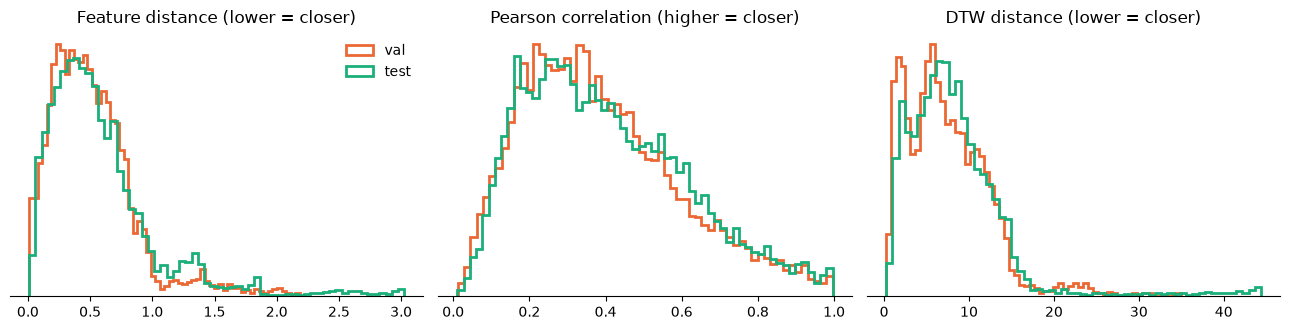

In [39]:
def sample_metric(matrix, rows, max_values=1_000_000, seed=0):
    rows = np.asarray(rows)
    n_rows = min(len(rows), max(1, max_values // n_templates))
    chosen = np.sort(np.random.default_rng(seed).choice(rows, size=n_rows, replace=False))
    return np.asarray(matrix[chosen]).ravel()

fig, axes = plt.subplots(1, len(METRICS), figsize=(13, 3.4))
for ax, (name, info) in zip(axes, METRICS.items()):
    for split in ('val', 'test'):
        values = sample_metric(metric_matrices[name], np.flatnonzero(query_split == split))
        ax.hist(values, bins=60, density=True, histtype='step', lw=2,
                color=SPLIT_COLORS[split], label=split)
    ax.set_title(f'{info["label"]} ({info["better"]} = closer)')
    ax.set_yticks([])
    ax.spines[['top', 'right', 'left']].set_visible(False)
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

**Interpretation.** For all three metrics, the validation and test distributions overlap almost exactly. The validation set is therefore a good stand-in for the test set: thresholds or hyperparameters tuned on validation distances should carry over without a systematic shift. The feature distance and DTW distributions are both right-skewed. Most windows sit close to their nearest match (feature distance ≈ 0.2–0.6, DTW ≈ 2–10), with a thin tail of poorly matched windows (feature distance > 1.5, DTW > 20). Those tail windows are likely unusual or rare consumption patterns, and they are the ones most likely to be hard to re-identify. Pearson correlation is much more spread out. Its mode is around 0.3, and only a small fraction of windows are above 0.8. So even the best-matching window often shares only a weak linear trend with the target, which suggests correlation separates windows less sharply than the distance-based metrics do. The small secondary bump in the test feature distances (≈ 1.2–1.4) has no clear match in the validation set and may be worth checking. It could come from a few households or a particular time period.

### Do the metrics agree?

For each query, every metric selects its best template: the minimum for distances, the maximum for correlation. The table shows how often two metrics select the **same** best template, which gives a quick sense of how different the metrics really are.

In [40]:
def best_template_positions(name):
    m = np.asarray(metric_matrices[name])
    return m.argmax(axis=1) if METRICS[name]['better'] == 'higher' else m.argmin(axis=1)

best_pos = {name: best_template_positions(name) for name in METRICS}
agreement = pd.DataFrame(
    [[np.mean(best_pos[a] == best_pos[b]) for b in METRICS] for a in METRICS],
    index=[METRICS[n]['label'] for n in METRICS], columns=[METRICS[n]['label'] for n in METRICS])
display(agreement.style.format('{:.1%}').set_caption('Share of queries where both metrics pick the same best template'))

,Feature distance,Pearson correlation,DTW distance
Feature distance,100.0%,6.2%,17.7%
Pearson correlation,6.2%,100.0%,5.2%
DTW distance,17.7%,5.2%,100.0%


### Example: best templates for one query

This figure shows how the metrics would be used for disaggregation. The top panel shows the query window's aggregate real power next to the best-matching template window chosen by each metric. The panels below show the **target appliances**: the query's true consumption, and the consumption recorded in each chosen template. The template's appliance curves are what a 1-nearest-neighbour pattern matcher would output as its estimate. Raw (un-normalized) values are plotted.

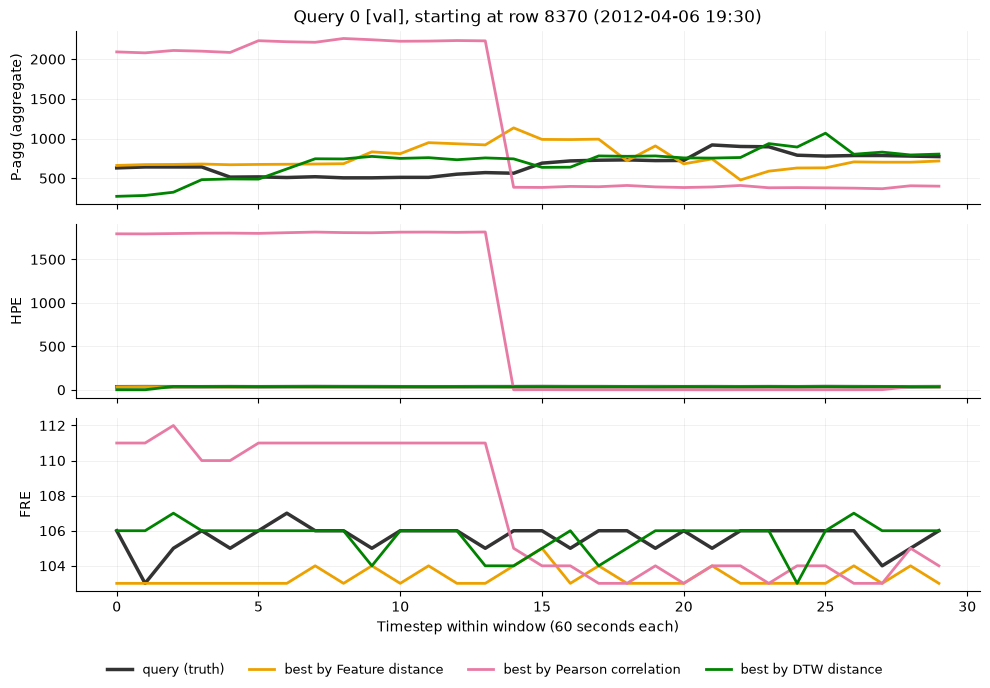

In [41]:
q = EXAMPLE_QUERY_POS
q_start = query_indices[q]
steps = np.arange(window_length)

n_panels = 1 + len(appliance_names)
fig, axes = plt.subplots(n_panels, 1, figsize=(10, 2.1 * n_panels + 0.6), sharex=True)
series = [(agg_data, 0, f'{electrical_quantities[0]} (aggregate)')] + \
         [(apps_data, k, name) for k, name in enumerate(appliance_names)]

for ax, (source, col, ylabel) in zip(axes, series):
    ax.plot(steps, source[q_start:q_start + window_length, col], color=QUERY_COLOR, lw=2.5, label='query (truth)')
    for name, info in METRICS.items():
        t_start = template_indices[best_pos[name][q]]
        ax.plot(steps, source[t_start:t_start + window_length, col], color=METRIC_COLORS[name], lw=2,
                label=f'best by {info["label"]}')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25, lw=0.5)
    ax.spines[['top', 'right']].set_visible(False)

title_time = f' ({datetimes[q_start]:%Y-%m-%d %H:%M})' if datetimes is not None else ''
axes[0].set_title(f'Query {q} [{query_split[q]}], starting at row {q_start}{title_time}')
axes[-1].set_xlabel(f'Timestep within window ({time_resolution} {time_units} each)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels), fontsize=9, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

### Example: DTW warping path

The DTW alignment between the example query and its DTW-best template, plotted for the first normalized channel. The template is drawn below the query with a vertical offset, and each gray line joins a pair of matched points on the optimal warping path. Slanted lines show where DTW stretched or shifted time to improve the match.

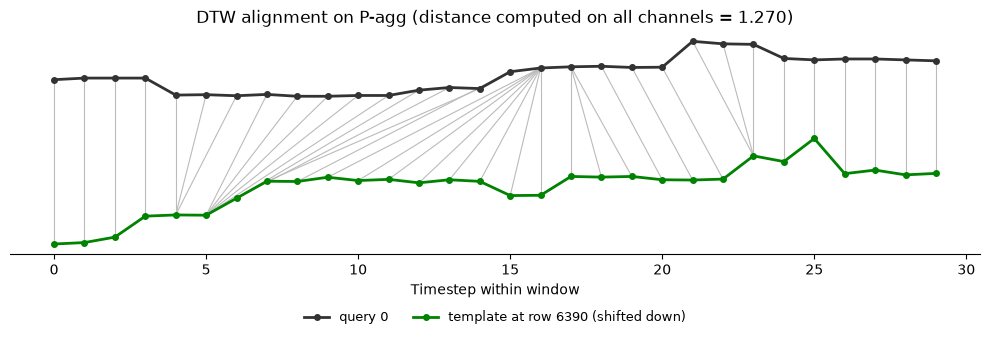

In [42]:
t = best_pos['dtw_distance'][q]
distance, path = dtw_with_path(query_windows[q], template_windows[t])
qa, ta = query_windows[q][:, 0], template_windows[t][:, 0]
offset = (ta.max() - qa.min()) + 0.4 * max(np.ptp(qa), np.ptp(ta), 1e-3)   # template sits fully below query

fig, ax = plt.subplots(figsize=(10, 3.6))
for i, j in path:
    ax.plot([i, j], [qa[i], ta[j] - offset], color='#bbbbbb', lw=0.8, zorder=1)
ax.plot(steps, qa, color=QUERY_COLOR, lw=2, marker='o', ms=4, label=f'query {q}', zorder=2)
ax.plot(steps, ta - offset, color=METRIC_COLORS['dtw_distance'], lw=2, marker='o', ms=4,
        label=f'template at row {template_indices[t]} (shifted down)', zorder=2)
ax.set_yticks([])
ax.set_xlabel('Timestep within window')
ax.set_title(f'DTW alignment on {electrical_quantities[0]} (distance computed on all channels = {distance:.3f})')
ax.legend(frameon=False, fontsize=9, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.2))
ax.spines[['top', 'right', 'left']].set_visible(False)
fig.tight_layout()
plt.show()

## 11. Save results

All outputs go to `results/<DATASET_NAME>/`:

| File | Contents |
|---|---|
| `feature_distance.npy`, `pearson_correlation.npy`, `dtw_distance.npy` | $(N_q, N_t)$ `float32` metric matrices (already on disk, flushed here) |
| `metric_index.npz` | `template_indices`, `query_indices`, `query_split`, plus settings (window length, features, DTW band) |
| `features.npz` | Template and query feature matrices, $(N, C, F)$ |
| `combined_metric_lookup.pkl`, `feature_lookup.pkl` | *Legacy format, small datasets only.* Same dictionaries as the old notebook, keyed by `(template_idx, query_idx)` and by window start respectively |

In [44]:
for m in metric_matrices.values():
    m.flush()

np.savez(
    os.path.join(results_dir, 'metric_index.npz'),
    dataset_name=DATASET_NAME,
    template_indices=template_indices,
    query_indices=query_indices,
    query_split=query_split,
    metric_names=np.array(list(METRICS)),
    metric_better=np.array([METRICS[n]['better'] for n in METRICS]),
    electrical_quantities=np.array(electrical_quantities),
    feature_names=np.array(FEATURE_NAMES),
    window_length=window_length,
    stride=stride,
    dtw_band=-1 if DTW_BAND is None else DTW_BAND)   # -1 means unconstrained

np.savez_compressed(
    os.path.join(results_dir, 'features.npz'),
    template_features=template_features.astype(np.float32),
    query_features=query_features.astype(np.float32),
    feature_names=np.array(FEATURE_NAMES),
    electrical_quantities=np.array(electrical_quantities))

## 12. Loading the results elsewhere

Copy these helpers into downstream notebooks. `load_metric_results` memory-maps the matrices, so even the two-year results open instantly. `lookup` reproduces the old `combined_lookup[(template_idx, query_idx)]` access pattern. For bulk work, index the matrices directly. For example, `np.argsort(metrics['dtw_distance'][q])[:k]` gives the column positions of the *k* closest templates for query row `q`.

The last cell reloads the files just written and checks them against the in-memory results.

In [45]:
def load_metric_results(results_dir, mmap=True):
    """Load metric matrices (memory-mapped by default) and the index arrays that label their rows/columns."""
    index = dict(np.load(os.path.join(results_dir, 'metric_index.npz')))
    metrics = {str(name): np.load(os.path.join(results_dir, f'{name}.npy'), mmap_mode='r' if mmap else None)
               for name in index['metric_names']}
    index['template_pos'] = {int(i): k for k, i in enumerate(index['template_indices'])}
    index['query_pos'] = {int(i): k for k, i in enumerate(index['query_indices'])}
    return metrics, index

def lookup(metrics, index, template_idx, query_idx):
    """All metric values for one (template start row, query start row) pair."""
    q, t = index['query_pos'][int(query_idx)], index['template_pos'][int(template_idx)]
    return {name: float(m[q, t]) for name, m in metrics.items()}

loaded_metrics, loaded_index = load_metric_results(results_dir)
example = lookup(loaded_metrics, loaded_index, template_indices[0], query_indices[0])
print(f'lookup(template_idx={template_indices[0]}, query_idx={query_indices[0]}) -> {example}')

for name in METRICS:
    assert np.array_equal(loaded_metrics[name], metric_matrices[name])
print('Reloaded results match.')

lookup(template_idx=2730, query_idx=8370) -> {'feature_distance': 0.06716417521238327, 'pearson_correlation': 0.47884422540664673, 'dtw_distance': 2.034274101257324}
Reloaded results match.


---
## Appendix: changes from the previous version

**Updated for the new `data_generation.py` output**
- Loads `processed_data/<DATASET_NAME>.npz` (one of the four generated datasets) instead of `ampds_dataset.npz`, and checks that every expected key is present.
- `agg_norm` and `apps_norm` no longer contain `time` and `id` columns, so the `[:, 2:]` slices and the `["id", "time"] + ...` column labels were removed.
- Uses the new `datetimes`, `agg_data`, `apps_data`, `chunk_size` and `num_chunks` fields to show real timestamps, raw-unit plots, and the chunk-based split. Also checks that no chunk appears in more than one split.
- `T` now counts the *unique timesteps covered by windows*, so it is labelled that way. The recording length comes from `len(datetimes)`.

**Fixes**
- The `rms` feature computed the mean square without taking the square root. It now returns true RMS.
- Feature distance used to compare each query against *every* window, including other validation and test windows. Only training windows are templates now, the same as for Pearson and DTW.
- Pearson correlation no longer returns `NaN` when a channel is flat within a window.

**Scaling and clean-up**
- The three metrics are vectorized (`cdist`, a z-score matrix product, and a DTW kernel batched over templates) instead of Python loops over every pair.
- Results are stored as on-disk $(N_q, N_t)$ matrices rather than dictionaries, so the two-year dataset fits in memory. The legacy pickles are still written for small datasets.
- `fastdtw` (approximate) was replaced by exact DTW, with an optional Sakoe–Chiba band. On the one-week dataset this step drops from about 4 minutes to under a second. This removes the `fastdtw` dependency. DTW values can be slightly lower than before.
- Added a configuration cell, sanity checks against reference implementations, metric distributions, a metric-agreement table, and example figures.